## Stationnarité

Ce notebook a été construit à partir de la source suivante : [*Practical Time Series Analysis, Prediction with Statistics & Machine Learning*, Aileen Nielsen, 2020](https://www.oreilly.com/library/view/practical-time-series/9781492041641/).

Pour rappel, les modèles courants de prédiction fonctionne sur des séries temporelles stationnaire. En pratique, cela veut dire que la série doit être "stable" dans le temps. Plus formellement, une série est stationnaire si ses propriétés statistiques ne changent pas au cours du temps. Les propriétés statistiques sont la moyenne, la variance, l'autocorrélation, ... 

Ainsi, une série avec une tendance ou bien une saisonnalité n'est pas stationnaire. 

Dans ce notebook, nous allons étudier :
1. comment tester si une méthode est stationnaire ou non stationnaire
2. comment transformer une série temporelle non stationnaire en série stationnaire

Quelques méthodes pour rendre une série stationnaire :
- application de fonction log, racine carré ou racine cubique, dans le cas où la variance des données change
- par différentiation, pour supprimer une tendance dans la série


## Load Serie

In [2]:
%run -i "../Loader.ipynb"
plt.rcParams['figure.figsize'] = [15, 8]

In [3]:
loader = Loader(dataDefaultPath="..", debug=False)

loader.loadSource(Loader.COINCODEX, forceEqualDate=True)

df = loader.get(Loader.COINCODEX, Loader.ADA)

print(df.dtypes)

serie = df.Close
serie

init loader: .. False
-----------------
path ===== ..\data\Coincodex\coin_Cardano.csv  &  ..
path ===== ..\data\Coincodex\coin_Aave.csv  &  ..
path ===== ..\data\Coincodex\coin_Bitcoin.csv  &  ..
path ===== ..\data\Coincodex\coin_Cosmos.csv  &  ..
path ===== ..\data\Coincodex\coin_Dogecoin.csv  &  ..
path ===== ..\data\Coincodex\coin_Ethereum.csv  &  ..
path ===== ..\data\Coincodex\coin_Litecoin.csv  &  ..
path ===== ..\data\Coincodex\coin_Monero.csv  &  ..
path ===== ..\data\Coincodex\coin_Polkadot.csv  &  ..
path ===== ..\data\Coincodex\coin_USDCoin.csv  &  ..
path ===== ..\data\Coincodex\coin_Microsoft.csv  &  ..
path ===== ..\data\Coincodex\coin_AT&T.csv  &  ..
path ===== ..\data\Coincodex\coin_cac40.csv  &  ..
path ===== ..\data\Coincodex\coin_Amazon.csv  &  ..
path ===== ..\data\Coincodex\coin_Tesla.csv  &  ..
High         float64
Low          float64
Open         float64
Close        float64
Volume       float64
Marketcap    float64
dtype: object


Date
2017-10-01    0.025808
2017-10-02    0.020827
2017-10-03    0.021973
2017-10-04    0.021512
2017-10-05    0.018481
                ...   
2022-10-19    0.340065
2022-10-20    0.348859
2022-10-21    0.351256
2022-10-22    0.361817
2022-10-23    0.357243
Name: Close, Length: 1849, dtype: float64

### Visualisation

Avant de tester la stationnarité de votre série, il est intéressant d'afficher quelques statistiques afin de vérifier si elle est stationnaire ou non.

Cela peut être fait en calculant une moyenne et une variance sur une fenêtre temporelle mobile donnée (moving average). Cette méthode de smoothing a déjà été présentée dans un précédent notebook.



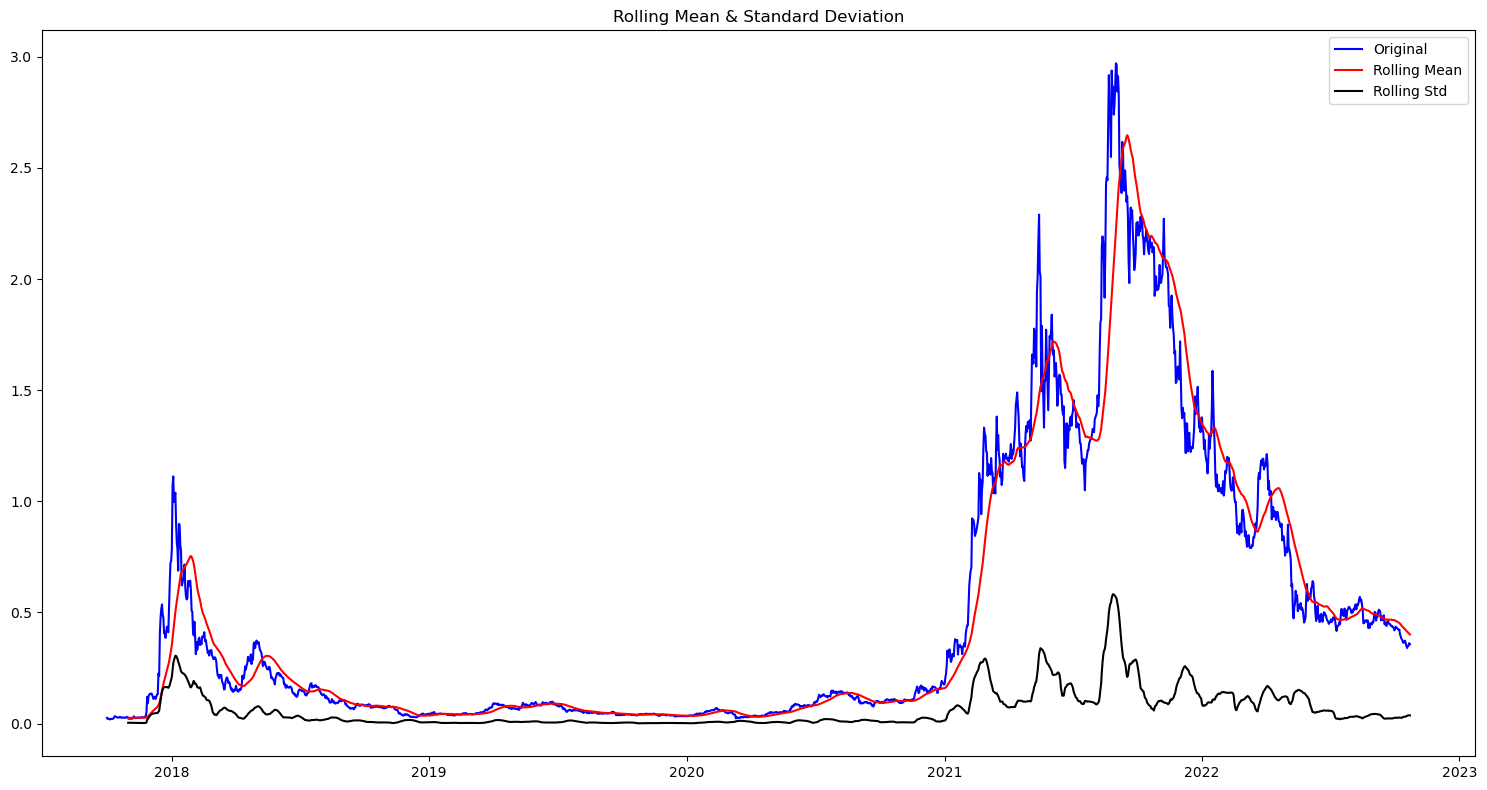

In [4]:

window = 31

rolmean = serie.rolling(window=window).mean()
rolstd = serie.rolling(window=window).std()

plt.plot(serie, color='blue',label='Original')
plt.plot(rolmean, color='red', label='Rolling Mean')
plt.plot(rolstd, color='black', label = 'Rolling Std')
plt.legend(loc='best')
plt.title('Rolling Mean & Standard Deviation')
plt.tight_layout()
plt.show()

Nous pouvons voir ici que ni la moyenne ni la variance ne semble stationnaire. Une autre méthode, basée sur le calcul, est aussi utilisable.

### Test de stationarité

Le test de Augmented Dickey–Fuller (ADF) est le plus utilisé pour vérifier la stationnarité d'une série temporelle. Nous vous fournissons la fonction suivante pour tester directement vos série.

La fonction prend en paramètre une série et un niveau de risque (par défaut "1%"), et retourne vrai si la série est stationnaire. Ce test est un test d'hypothèse : l'hypothèse nulle est que la série est stationnaire et l'hypothèse alternative est que la série est non stationnaire. Le paramètre "risk" indique le risque que nous sommes prêt à prendre si l'on refuse la mauvaise hypothèse. Plus le risque est petit, plus on augmente nos chances de ne pas se tromper sur notre choix de l'hypothèse retenue.

En pratique, cette fonction vous affichera les valeurs critiques pour chaque niveau de risque. Pour que la série soit stationnaire, il faut vérifier que le test statistique soit inférieure à la valeur critique associée à votre niveau de risque.

Voici la fonction pour calculer le test de Dickey–Fuller (ADF) :

In [ ]:
def testStationnairy(serie, risk="1%"):
    '''
    @param risk: "1%", "5%", "10%"
    '''

    result = adfuller (serie)
    
    print('Test Statistic: %f' %result[0])
    print('p-value: %f' %result[1])
    print('Critical values:')
    for key, value in result[4].items ():
        print('\t%s: %.3f' %(key, value))

    testStatistic = result[0]
    criticalValue = result[4][risk]

    print("Test : ", testStatistic , "(Test Statistic) < ", criticalValue, " (1% critical value) ?")

    return testStatistic < criticalValue

On peut ainsi tester notre série :

In [ ]:
testStationnairy(data.Close)

Sans rentrer dans les détails, voici comment nous allons utiliser ce test: si elle retourne `False` alors la série n'est pas stationnaire. Il est ainsi nécessaire d'appliquer des transformations pour rendre cette série stationnaire.

Pour ce faire, plusieurs méthodes sont possibles :
- décomposer la série temporelle via sa tendance, sa saisonnalité et son résidu (méthode vue dans un précédent Notebook)
- travailler sur les différences terme à terme de la série
- appliquer une fonction log, racine carré, racine cubique, ...

Vous avez maintenant les compétences pour réaliser de tels traitements. Vous allez donc dans la suite appliquer ces traitements sur vos données de sécurité et vérifier si la série devient stationnaire ou non.

### Différenciation

Le premier test concerne l'approche par différenciation : au lieu d'étudier la série initiale, nous allons étudier celle de la différence de terme à terme. 

Cette méthode est très courante et cela s'explique par les raisons suivantes :
- elle est simple à mettre en oeuvre
- elle permet toujours de faire de la prédiction sur nos données, puisque on peut facilement récupérer la prédiction t+1, en ajoutant la différence prédite à la donnée de l'instant t 

**Questions** :
1. consulter la document de `DataFrame.diff(periods=1, axis=0)`
2. générer la série temporelle par différenciation
3. afficher les 2 série sur un même graphique
4. tester si la série par différentiation est stationnaire
5. si non, ré-appliquer une différentiation sur la série déjà obtenue et re-tester la différentiation

In [ ]:
# diff


In [ ]:
# afficher


In [ ]:
# test stationnarite


### Log & racine

Une autre méthode consiste à appliquer les fonctions log, racine, racine cubique sur la série.


### Questions
1. générer les séries temporelles
2. afficher les séries. Ont-elle l'air plus stationnaire que la version initiale ?
3. vérifier si elles sont stationnaires ou non

In [ ]:
# génération des séries - utiliser numpy.log, numpy.sqrt, ...


In [ ]:
# affichage 


In [ ]:
# test stationnarité
